In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

# Project paths
PROJECT_DIR = Path("..").resolve()
DATASET_DIR = Path(r"D:\SoilDatasets\dataset_v3")
MANIFEST_PATH = PROJECT_DIR / "dataset" / "soil_image_manifest.csv"

# Image configuration
IMAGE_SIZE = (224, 224)
CLASS_NAMES = ["Clay", "Loam", "Sand"]

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Manifest:", MANIFEST_PATH)
print("Dataset exists:", DATASET_DIR.exists())
print("Manifest exists:", MANIFEST_PATH.exists())

Project directory: D:\J26-IT-433-Soil-Assessment\J26-IT-433-Soil-Assessment-Planner\component1
Dataset directory: D:\SoilDatasets\dataset_v3
Manifest: D:\J26-IT-433-Soil-Assessment\J26-IT-433-Soil-Assessment-Planner\component1\dataset\soil_image_manifest.csv
Dataset exists: True
Manifest exists: True


In [3]:
df = pd.read_csv(MANIFEST_PATH)

print("Total records:", len(df))
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Total records: 92050

Columns:
['image_path', 'split', 'soil_class', 'class_id']


,image_path,split,soil_class,class_id
0,train/Clay/123b85296021_0000.jpg,train,Clay,0
1,train/Clay/123b85296021_0001.jpg,train,Clay,0
2,train/Clay/123b85296021_0002.jpg,train,Clay,0
3,train/Clay/123b85296021_0003.jpg,train,Clay,0
4,train/Clay/123b85296021_0004.jpg,train,Clay,0


In [4]:
def get_image_path(relative_path):
    return DATASET_DIR / Path(relative_path)

df["full_path"] = df["image_path"].apply(get_image_path)

exists_count = df["full_path"].map(Path.exists).sum()

print("Total records:", len(df))
print("Existing images:", exists_count)
print("Missing images:", len(df) - exists_count)

Total records: 92050
Existing images: 92050
Missing images: 0


In [5]:
# Check sample image properties

sample_row = df.iloc[0]
sample_path = sample_row["full_path"]

image = Image.open(sample_path).convert("RGB")
image_array = np.array(image)

print("Image:", sample_path)
print("Size:", image.size)
print("Mode:", image.mode)
print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

Image: D:\SoilDatasets\dataset_v3\train\Clay\123b85296021_0000.jpg
Size: (224, 224)
Mode: RGB
Array shape: (224, 224, 3)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


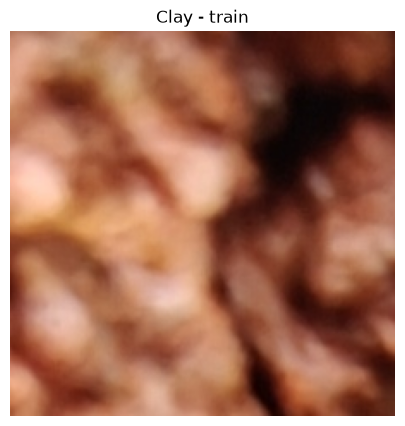

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(f"{sample_row['soil_class']} - {sample_row['split']}")
plt.axis("off")
plt.show()

In [7]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [8]:
%pip install tensorflow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [10]:
from pathlib import Path
import pandas as pd
import numpy as np

# Dataset configuration
DATASET_DIR = Path(r"D:\SoilDatasets\dataset_v3")
MANIFEST_PATH = Path("../dataset/soil_image_manifest.csv")

IMAGE_SIZE = (224, 224)
CLASS_NAMES = ["Clay", "Loam", "Sand"]

# Load manifest
df = pd.read_csv(MANIFEST_PATH)

print("Dataset exists:", DATASET_DIR.exists())
print("Manifest exists:", MANIFEST_PATH.exists())
print("Total records:", len(df))

Dataset exists: True
Manifest exists: True
Total records: 92050


In [11]:
def load_image(image_path, label):
    # Convert the relative path to a full path
    image_path = tf.strings.join(
        [tf.constant(str(DATASET_DIR)), image_path],
        separator="/"
    )

    # Read image
    image = tf.io.read_file(image_path)

    # Decode JPG as RGB
    image = tf.image.decode_jpeg(image, channels=3)

    # Resize
    image = tf.image.resize(image, IMAGE_SIZE)

    # Normalize pixels to [0, 1]
    image = tf.cast(image, tf.float32) / 255.0

    # Convert label to integer
    label = tf.cast(label, tf.int32)

    return image, label


print("Image loader ready.")

Image loader ready.


In [12]:
test_path = tf.constant("train/Clay/123b85296021_0000.jpg")
test_label = tf.constant(0.0)

test_image, test_label = load_image(test_path, test_label)

print("Image shape:", test_image.shape)
print("Image dtype:", test_image.dtype)
print("Label:", test_label.numpy())
print("Label dtype:", test_label.dtype)

Image shape: (224, 224, 3)
Image dtype: <dtype: 'float32'>
Label: 0
Label dtype: <dtype: 'int32'>


In [13]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 70233
Validation: 10729
Test: 11088


In [14]:
# Recreate the raw TensorFlow datasets

train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_df["image_path"].values,
        train_df["class_id"].values
    )
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (
        val_df["image_path"].values,
        val_df["class_id"].values
    )
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (
        test_df["image_path"].values,
        test_df["class_id"].values
    )
)

print("Raw datasets recreated successfully.")
print("Train:", train_dataset.element_spec)
print("Validation:", val_dataset.element_spec)
print("Test:", test_dataset.element_spec)

Raw datasets recreated successfully.
Train: (TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))
Validation: (TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))
Test: (TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))


In [15]:
import pandas as pd
from pathlib import Path

# Manifest is stored inside the project
MANIFEST_PATH = Path("../dataset/soil_image_manifest.csv")

df = pd.read_csv(MANIFEST_PATH)

# Recreate split DataFrames
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

print("DataFrames recreated successfully.")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

DataFrames recreated successfully.
Train: 70233
Validation: 10729
Test: 11088


In [16]:
# Extract image paths and labels

train_paths = train_df["image_path"].values
train_labels = train_df["class_id"].values

val_paths = val_df["image_path"].values
val_labels = val_df["class_id"].values

test_paths = test_df["image_path"].values
test_labels = test_df["class_id"].values

print("Paths and labels extracted successfully.")
print("Train:", len(train_paths), len(train_labels))
print("Validation:", len(val_paths), len(val_labels))
print("Test:", len(test_paths), len(test_labels))

Paths and labels extracted successfully.
Train: 70233 70233
Validation: 10729 10729
Test: 11088 11088


In [17]:
# Create raw TensorFlow datasets

train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

print("Raw TensorFlow datasets created successfully.")

Raw TensorFlow datasets created successfully.


In [18]:
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)

print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)

Batch size: 32
Image size: (224, 224)


In [20]:
# Create safe preprocessing pipelines

train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

# Training pipeline
train_dataset = (
    train_dataset
    .shuffle(2000, reshuffle_each_iteration=True)
    .map(load_image, num_parallel_calls=1)
    .batch(BATCH_SIZE)
)

# Validation pipeline
val_dataset = (
    val_dataset
    .map(load_image, num_parallel_calls=1)
    .batch(BATCH_SIZE)
)

# Test pipeline
test_dataset = (
    test_dataset
    .map(load_image, num_parallel_calls=1)
    .batch(BATCH_SIZE)
)

print("Safe preprocessing pipelines created successfully.")

Safe preprocessing pipelines created successfully.


In [21]:
# Verify one batch

images, labels = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Image data type:", images.dtype)
print("Label batch shape:", labels.shape)
print("Label data type:", labels.dtype)
print("Pixel minimum:", tf.reduce_min(images).numpy())
print("Pixel maximum:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Image data type: <dtype: 'float32'>
Label batch shape: (32,)
Label data type: <dtype: 'int32'>
Pixel minimum: 0.0
Pixel maximum: 1.0


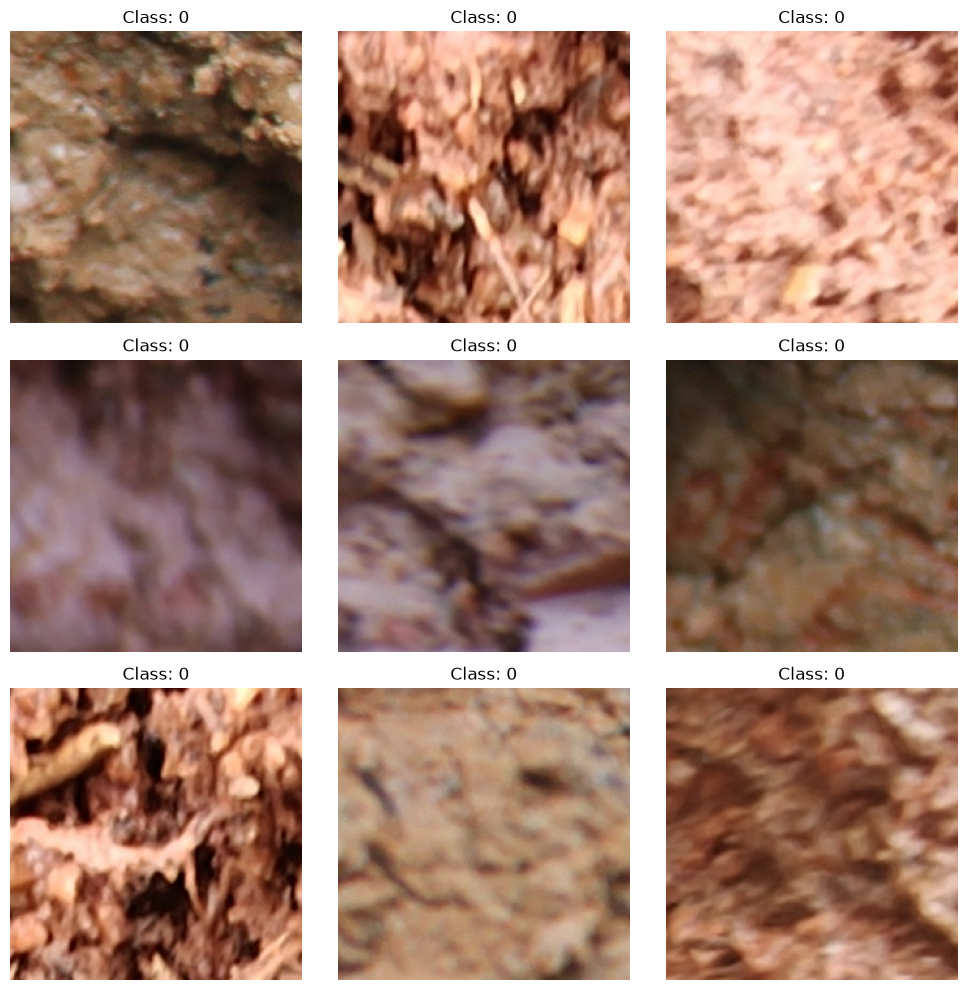

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    plt.title(f"Class: {labels[i].numpy()}")
    plt.axis("off")

plt.tight_layout()
plt.show()

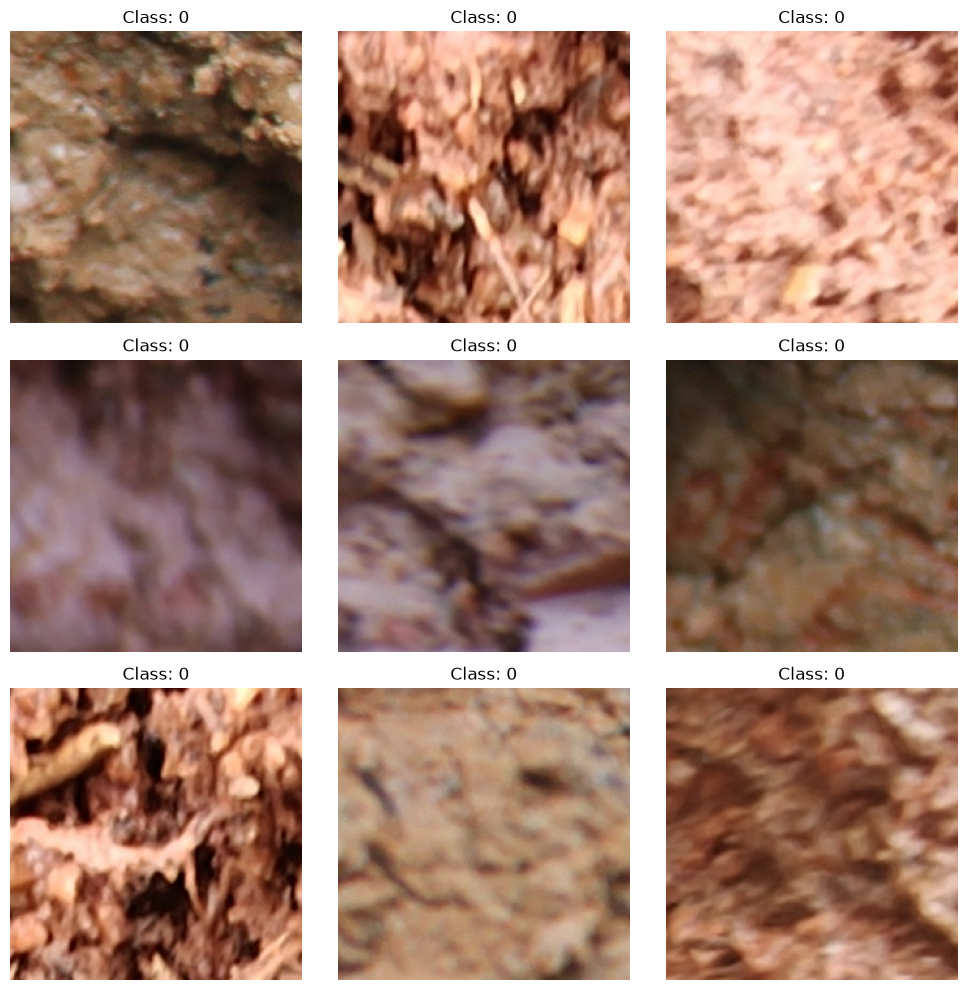

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    plt.title(f"Class: {labels[i].numpy()}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
print("===== IMAGE PREPROCESSING SUMMARY =====")
print("Image size       :", IMAGE_SIZE)
print("Batch size       :", BATCH_SIZE)
print("Image channels   : 3 (RGB)")
print("Image dtype      : float32")
print("Pixel range      : 0.0 - 1.0")
print("Label dtype      : int32")
print("Train images     :", len(train_df))
print("Validation images:", len(val_df))
print("Test images      :", len(test_df))
print("Classes          : 3")
print("Class mapping    : 0=Clay, 1=Loam, 2=Sand")
print("========================================")

===== IMAGE PREPROCESSING SUMMARY =====
Image size       : (224, 224)
Batch size       : 32
Image channels   : 3 (RGB)
Image dtype      : float32
Pixel range      : 0.0 - 1.0
Label dtype      : int32
Train images     : 70233
Validation images: 10729
Test images      : 11088
Classes          : 3
Class mapping    : 0=Clay, 1=Loam, 2=Sand
